In [1]:
import matplotlib.pyplot as plt
import pandas as pd

## Data Loading

In [2]:
df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [4]:
df.shape

(541909, 8)

## Data Cleaning

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df["CustomerID"] = df["CustomerID"].astype("Int64")

In [7]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df['Description'] = df['Description'].fillna('Unknown')

In [9]:
df = df.dropna(subset=['CustomerID'])

In [10]:
df.isna().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(5225)

In [12]:
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Date"] = df["InvoiceDate"].dt.strftime("%d.%m.%Y")
df["Time"] = df["InvoiceDate"].dt.strftime("%H:%M:%S")

In [15]:
df[["InvoiceDate","Date","Time"]]

,InvoiceDate,Date,Time
0,2010-12-01 08:26:00,01.12.2010,08:26:00
1,2010-12-01 08:26:00,01.12.2010,08:26:00
2,2010-12-01 08:26:00,01.12.2010,08:26:00
3,2010-12-01 08:26:00,01.12.2010,08:26:00
4,2010-12-01 08:26:00,01.12.2010,08:26:00
...,...,...,...
541904,2011-12-09 12:50:00,09.12.2011,12:50:00
541905,2011-12-09 12:50:00,09.12.2011,12:50:00
541906,2011-12-09 12:50:00,09.12.2011,12:50:00
541907,2011-12-09 12:50:00,09.12.2011,12:50:00


In [16]:
df['Quantity'].min()

-80995

In [17]:
df['Quantity'].max()

80995

In [18]:
df[df["Quantity"] == -80995]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Date,Time
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom,09.12.2011,09:27:00


In [19]:
df[df["Quantity"] == 80995]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Date,Time
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,09.12.2011,09:15:00


In [20]:
(df["Quantity"] < 0).sum()

np.int64(8872)

### Проверка количества товаров (Quantity)

Я проверила минимальное и максимальное значения **Quantity**, чтобы выявить необычные операции и понять, нужно ли учитывать их при анализе продаж.
Минимальное значение составило **−80 995**, а максимальное - **80 995**.
При изучении этих записей выяснилось, что они относятся к одному клиенту и одному товару. Через 12 минут после покупки была оформлена отмена на такое же количество товара.
Это показывает, что отрицательные значения **Quantity** могут обозначать отменённые заказы или возвраты. Поэтому такие операции необходимо учитывать отдельно, чтобы правильно рассчитывать выручку.

In [21]:
df["UnitPrice"].min()

0.0

In [22]:
df["UnitPrice"].max()

38970.0

In [23]:
(df["UnitPrice"] <= 0).sum()

np.int64(40)

In [24]:
df[df["UnitPrice"] == 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Date,Time
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647,Germany,05.12.2010,14:02:00
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560,United Kingdom,16.12.2010,14:36:00
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911,EIRE,21.12.2010,13:45:00
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081,United Kingdom,06.01.2011,16:41:00
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081,United Kingdom,06.01.2011,16:41:00


## Data Analysis

In [25]:
df_sales = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

df_sales.shape

(392692, 10)

In [26]:
df_sales["Revenue"] = df_sales["Quantity"] * df_sales["UnitPrice"]
df_sales[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [27]:
df_sales["Revenue"].sum()

np.float64(8887208.894000001)

In [28]:
df_sales["Month"] = df_sales["InvoiceDate"].dt.to_period("M")
monthly_sales = df_sales.groupby("Month")["Revenue"].sum()
monthly_sales

Month
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Revenue, dtype: float64

In [29]:
print("Best month:", monthly_sales.idxmax())
print("Highest sales:", monthly_sales.max())

Best month: 2011-11
Highest sales: 1156205.61


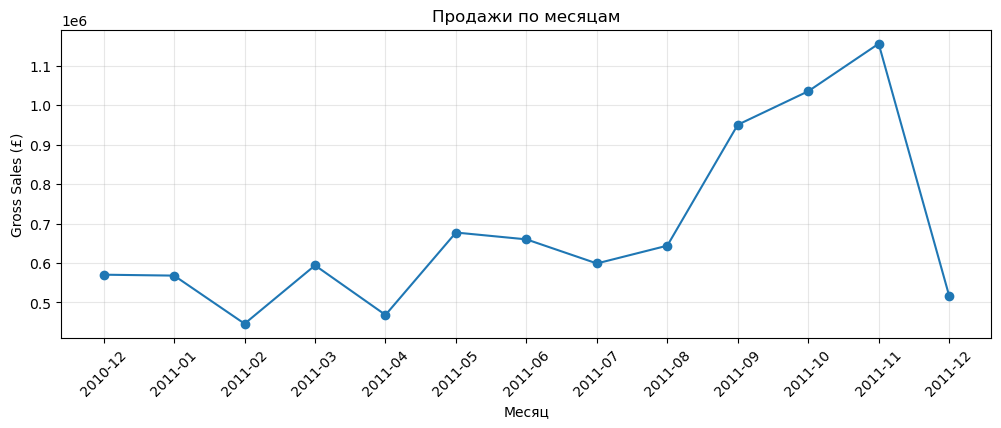

In [30]:
plt.figure(figsize=(12, 4))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Продажи по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Gross Sales (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

Продажи по месяцам

На этом этапе мы анализируем динамику продаж по месяцам, чтобы определить периоды с наибольшей и наименьшей суммой покупок, а также выявить возможные сезонные изменения.
Для анализа мы сгруппировали транзакции по месяцам и рассчитали общую стоимость покупок (Revenue) за каждый месяц.

In [31]:
country_sales = (
    df_sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

country_sales.head(10)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

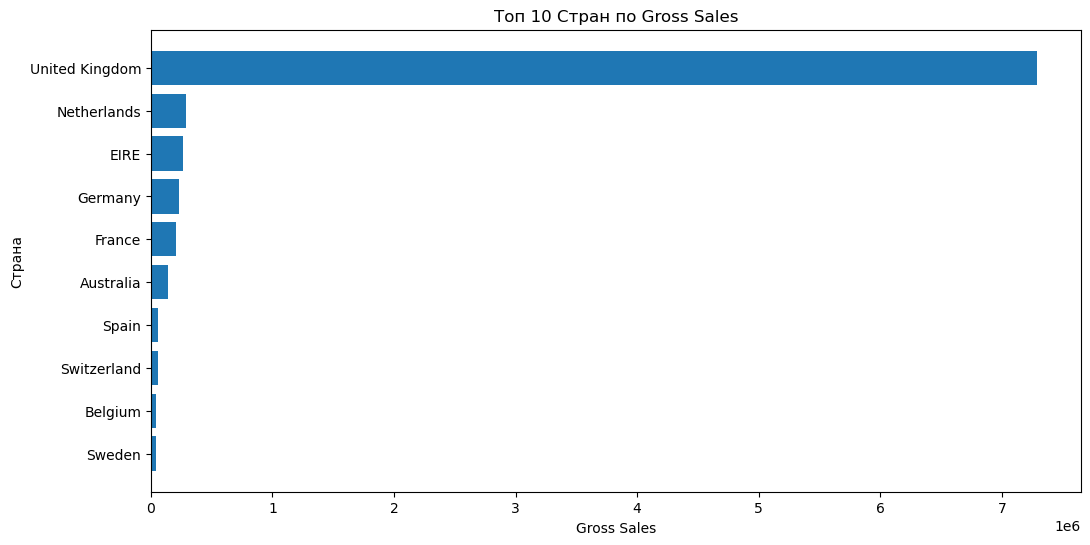

In [32]:
top10_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top10_countries.index,
    top10_countries.values
)

plt.title("Топ 10 Стран по Gross Sales")
plt.xlabel("Gross Sales")
plt.ylabel("Страна")

plt.gca().invert_yaxis()
plt.show()

Наибольшая сумма продаж приходится на Великобританию (7,29 млн фунт). На втором и третьем местах - Нидерланды (285 тыс.фунт) и Ирландия (265 тыс.фунт).
Основная часть продаж сосредоточена в Великобритании, что показывает сильную зависимость магазина от внутреннего рынка.

In [33]:
top_prod = (
    df_sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_prod

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64

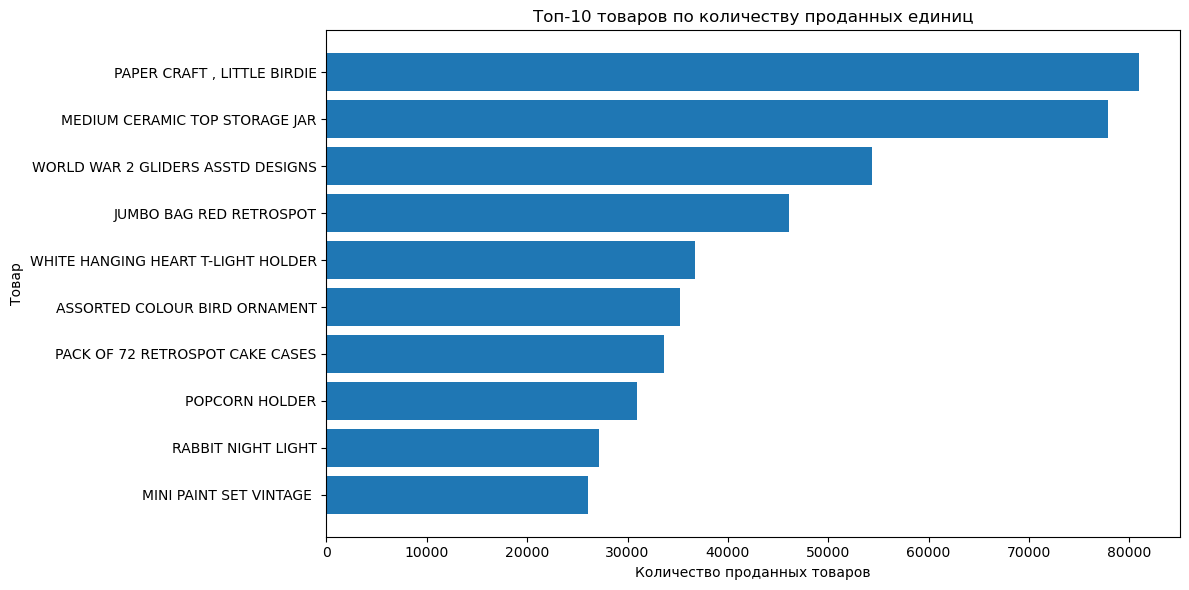

In [34]:
plt.figure(figsize=(12, 6))

plt.barh(top_prod.index, top_prod.values)

plt.title("Топ-10 товаров по количеству проданных единиц")
plt.xlabel("Количество проданных товаров")
plt.ylabel("Товар")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [35]:
net_product = (
    df[df["UnitPrice"] > 0]
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

net_product.head(10)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53119
JUMBO BAG RED RETROSPOT               44963
ASSORTED COLOUR BIRD ORNAMENT         35215
WHITE HANGING HEART T-LIGHT HOLDER    34128
PACK OF 72 RETROSPOT CAKE CASES       33386
POPCORN HOLDER                        30492
RABBIT NIGHT LIGHT                    27045
MINI PAINT SET VINTAGE                25880
PACK OF 12 LONDON TISSUES             25305
PACK OF 60 PINK PAISLEY CAKE CASES    24129
Name: Quantity, dtype: int64

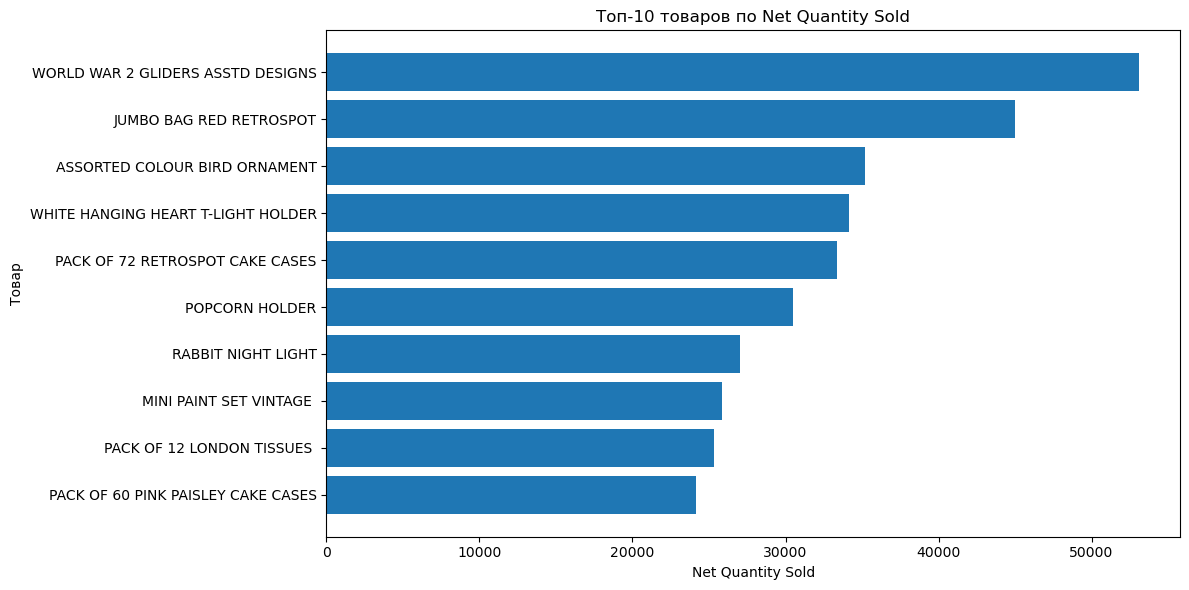

In [36]:
top10_net_products = net_product.head(10)

plt.figure(figsize=(12, 6))

plt.barh(top10_net_products.index, top10_net_products.values)

plt.title("Топ-10 товаров по Net Quantity Sold")
plt.xlabel("Net Quantity Sold")
plt.ylabel("Товар")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Сначала мы определили самые продаваемые товары без учёта возвратов. Однако товар PAPER CRAFT, LITTLE BIRDIE оказался на первом месте из-за крупной покупки на 80 995 единиц, которая позже была полностью отменена.
Поэтому мы повторно рассчитали количество проданных товаров, учитывая отрицательные значения Quantity (возвраты и отмены).
После этого рейтинг изменился: первое место занял WORLD WAR 2 GLIDERS ASSTD DESIGNS (53 119 шт.).
Таким образом, учёт возвратов позволяет точнее оценить фактическое количество проданных товаров.

In [37]:
df["NetRevenue"] = df["Quantity"] * df["UnitPrice"]

top_net_sales = (
    df.groupby("Description")["NetRevenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_net_sales

Description
REGENCY CAKESTAND 3 TIER              132567.70
WHITE HANGING HEART T-LIGHT HOLDER     93767.80
JUMBO BAG RED RETROSPOT                83056.52
PARTY BUNTING                          67628.43
POSTAGE                                66710.24
ASSORTED COLOUR BIRD ORNAMENT          56331.91
RABBIT NIGHT LIGHT                     51042.84
CHILLI LIGHTS                          45915.41
PAPER CHAIN KIT 50'S CHRISTMAS         41423.78
PICNIC BASKET WICKER 60 PIECES         39619.50
Name: NetRevenue, dtype: float64

Самым продаваемым товаром по количеству стал WORLD WAR 2 GLIDERS ASSTD DESIGNS (53 119 шт.), а наибольшую выручку принёс REGENCY CAKESTAND 3 TIER (132 567,70 фунт).
Это показывает, что количество проданных товаров не всегда связано с размером выручки.

In [38]:
total_customers = df_sales["CustomerID"].nunique()
print("Total customers:", total_customers)

Total customers: 4338


In [39]:
top_customers = (
    df_sales.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

CustomerID
14646    280206.02
18102    259657.30
17450    194390.79
16446    168472.50
14911    143711.17
12415    124914.53
14156    117210.08
17511     91062.38
16029     80850.84
12346     77183.60
Name: Revenue, dtype: float64

В датасете обнаружено 4 338 уникальных покупателей, совершивших покупки.
Сначала мы определили покупателей с наибольшей общей суммой покупок. Однако эти значения не учитывают возвраты.
Поэтому дополнительно рассчитываем сумму продаж с учётом возвратов, чтобы точнее оценить вклад каждого покупателя.

In [40]:
top_customers_net = (
    df.groupby("CustomerID")["NetRevenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers_net

CustomerID
14646    279489.02
18102    256438.49
17450    187322.17
14911    132458.73
12415    123725.45
14156    113214.59
17511     88125.38
16684     65892.08
13694     62690.54
15311     59284.19
Name: NetRevenue, dtype: float64

Наибольшую сумму продаж с учётом возвратов принёс покупатель 14646 (279 489 фунт).
После учёта возвратов рейтинг изменился: покупатель 16446, ранее занимавший четвёртое место, выбыл из топ-10 из-за крупной отменённой покупки.

In [41]:
purchase_frequency = (
    df_sales.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

purchase_frequency.head(10)

CustomerID
12748    209
14911    201
17841    124
13089     97
14606     93
15311     91
12971     86
14646     73
16029     63
13408     62
Name: InvoiceNo, dtype: int64

Больше всего заказов совершил покупатель 12748 (209 заказов), за ним следует 14911 (201 заказ).
При этом покупатель 14646, принёсший наибольшую сумму продаж, совершил 73 заказа.
Таким образом, покупатели с наибольшим количеством заказов не обязательно приносят магазину больше всего денег.

In [42]:
returns = df[(df["Quantity"] < 0) & (df["UnitPrice"] > 0)].copy()

df["NetRevenue"] = df["Quantity"] * df["UnitPrice"]
return_records = len(returns)
gross_sales = df_sales["Revenue"].sum()
total_returns = -(returns["Quantity"] * returns["UnitPrice"]).sum()
net_sales = gross_sales - total_returns

print("Return Records:",return_records)
print("Gross Sales:",gross_sales)
print("Total Returns:",total_returns)
print("Net Sales:",net_sales)

Return Records: 8872
Gross Sales: 8887208.894000001
Total Returns: 608689.47
Net Sales: 8278519.4240000015


В датасете обнаружено **8 872 записи с возвратами и отменами** на общую сумму 608 689,47 фунт.
До учёта возвратов сумма продаж составляла 8,89 млн фунт, после - 8,28 млн фунт.
Таким образом, возвраты и отмены уменьшили сумму продаж примерно на **6,85%**.

## Conclusion

В ходе проекта были проанализированы продажи интернет-магазина, популярные товары и поведение покупателей.

Основные результаты:

Наибольшая сумма продаж наблюдалась в ноябре 2011 года - 1,16 млн фунт
Большая часть продаж приходится на Великобританию
Самым продаваемым товаром по количеству стал WORLD WAR 2 GLIDERS ASSTD DESIGNS, а наибольшую сумму продаж принёс REGENCY CAKESTAND 3 TIER.
В датасете обнаружено 4 338 уникальных покупателей. Покупатели с наибольшим количеством заказов не всегда приносят больше всего денег.
Возвраты и отмены уменьшили сумму продаж примерно на 6,85% - с 8,89 млн фунт до £8,28 млн фунт.

Рекомендации:
На основе результатов можно рекомендовать магазину подробнее изучить причины роста продаж осенью, учитывать не только количество проданных товаров, но и их вклад в выручку, а также исследовать причины возвратов и отмен заказов.